In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor

from sklearn.preprocessing import PolynomialFeatures, StandardScaler, StandardScaler

from sklearn.metrics import r2_score

from sklearn.pipeline import Pipeline 

In [2]:
X=6*np.random.rand(200,1)-3
y=0.8*X**2 + 0.9*X + 2 + np.random.rand(200,1) 

#y=0.8x^2 + 0.9x + 2

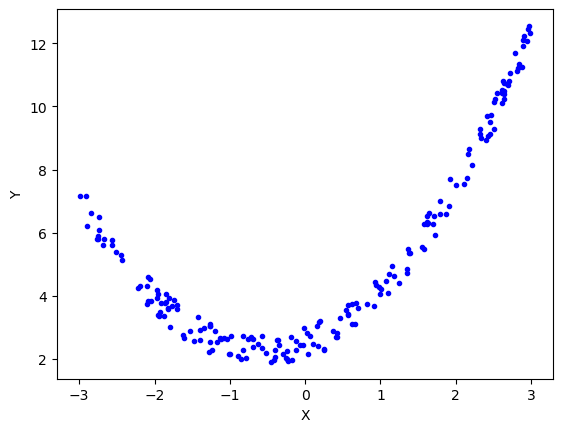

In [3]:
plt.plot(X,y,"b.")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [4]:
X_train,X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2, random_state=2
)

In [5]:
lr=LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[1.17]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[5.02]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[22.36]


In [6]:
y_predict=lr.predict(X_test)
print(f"R2_Score : {r2_score(y_test,y_predict)}")

R2_Score : 0.46236146592781946


<Axes: >

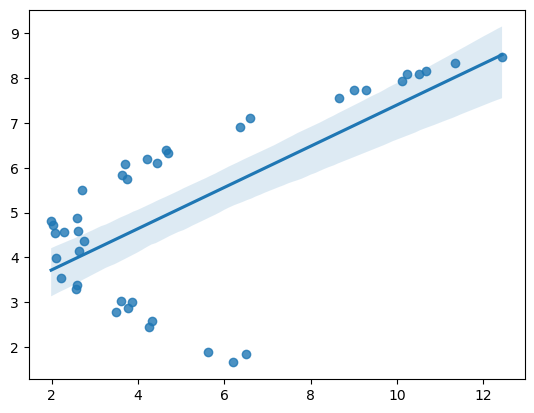

In [7]:
sns.regplot(x=y_test,y=y_predict)

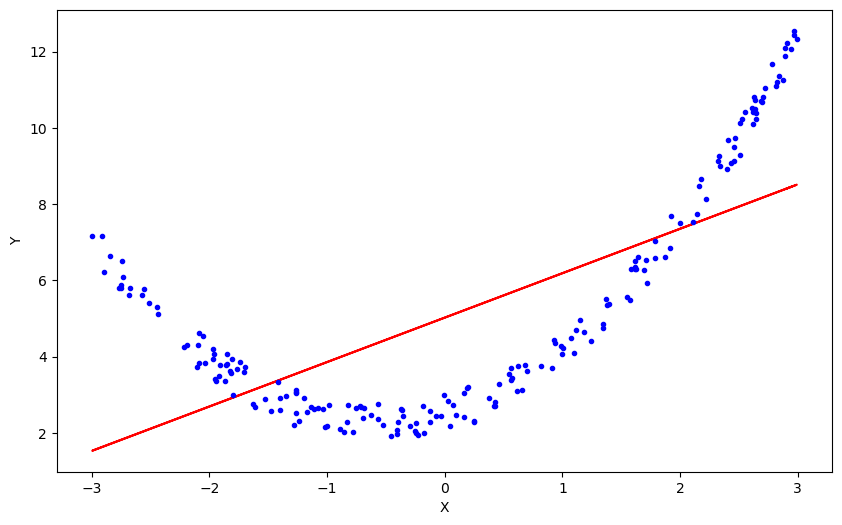

In [8]:
plt.figure(figsize=(10,6))
plt.plot(X_train, lr.predict(X_train), color="r")
plt.plot(X,y,"b.")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

# Applying Polynomial Regresson
# Degree = 2

In [9]:
poly=PolynomialFeatures(degree=2,include_bias=False)
X_train_trans = poly.fit_transform(X_train)
X_test_trans=poly.transform(X_test)

In [10]:
print(X_train[0])
print(X_train_trans[0])

[2.94205473]
[2.94205473 8.65568605]


In [11]:
print(X_test[0])
print(X_test_trans[0])

[-1.85699909]
[-1.85699909  3.44844563]


In [12]:
lr2=LinearRegression()
lr2.fit(X_train_trans,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 2)","[[0.89,0.8 ]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[2.53]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[35.6 ,21.47]"


In [13]:
y_predict_poly=lr2.predict(X_test_trans)
print("Coefficient : ",lr2.coef_)
print("Intercpet : ", lr2.intercept_)

Coefficient :  [[0.88820713 0.80390774]]
Intercpet :  [2.53258865]


In [14]:
print("R2_score",r2_score(y_test,y_predict_poly))

R2_score 0.9909678743198779


<Axes: >

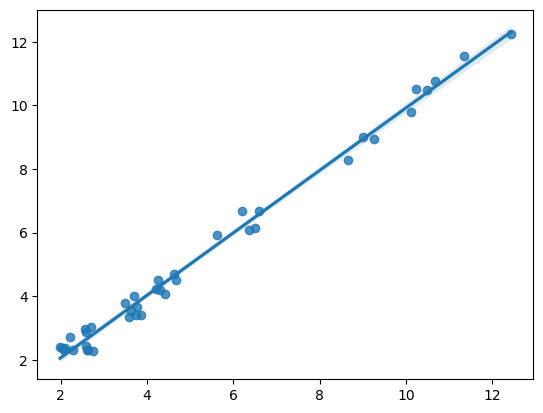

In [15]:
sns.regplot(x=y_test,y=y_predict_poly)

<Axes: >

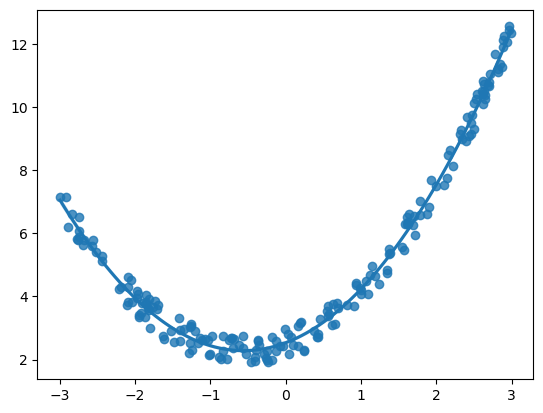

In [16]:
sns.regplot(x=X,y=y,order=2)

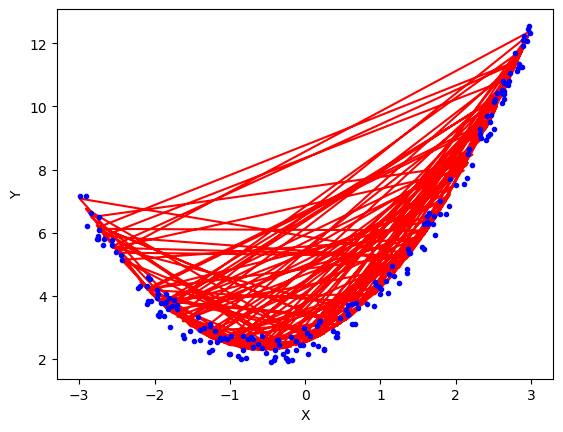

In [17]:
plt.plot(X_train ,lr2.predict(X_train_trans), color="r")
plt.plot(X,y,"b.")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [18]:

x_new=np.linspace(-3,3,200).reshape(200,1)
x_new_poly=poly.transform(x_new)
y_new_predict=lr2.predict(x_new_poly)

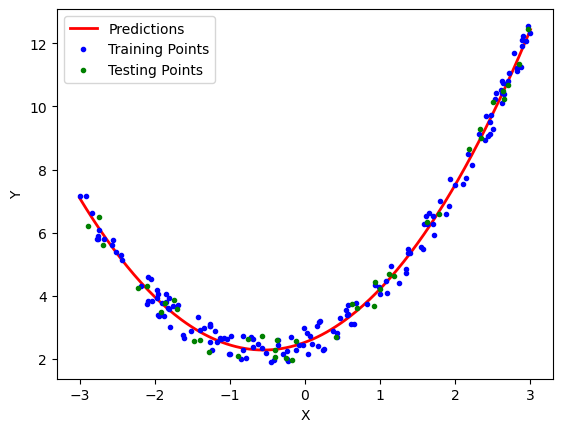

In [36]:
plt.plot(x_new, y_new_predict, "r-", linewidth=2, label="Predictions")
plt.plot(X_train, y_train, "b.", label="Training Points")
plt.plot(X_test, y_test, "g.", label="Testing Points")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()

plt.show()

In [37]:
def polynomial_regression(degre):
    X_new=np.linspace(-3,3,100).reshape(100,1)
    x_new_poly=poly.transform(X_new)
    
    polybig_features = PolynomialFeatures(degree=degre, include_bias=False)
    std_scaler=StandardScaler()
    lin_reg=LinearRegression()
    polynomial_regression=Pipeline(
        [
            ("Poly_features", polybig_features),
            ("std_scaler",std_scaler),
            ("lin_reg", lin_reg),
        ]
    )
    
    polynomial_regression.fit(X,y)
    y_newbig = polynomial_regression.predict(X_new)
    
    plt.plot(X_new, y_newbig, "r", label="Degree" + str(degre),linewidth=2)
    
    plt.plot(X_train, y_train, "b." , linewidth=3)
    plt.plot(X_test, y_test, "g." , linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-3,3,0,10])
    plt.show()
    

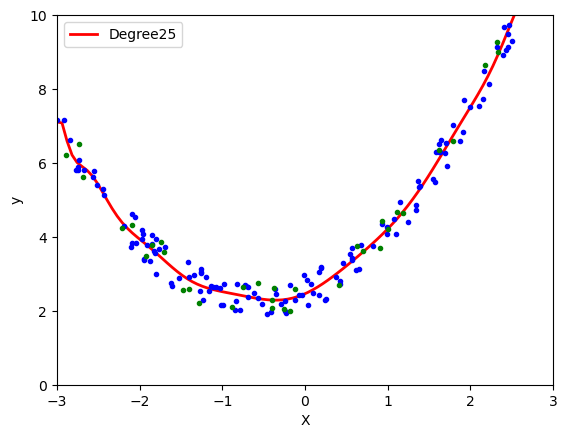

In [43]:
polynomial_regression(25)

# 3d polynomial regression

In [3]:
x= 7 * np.random.rand(100,1) -2.8
y= 7 * np.random.rand(100,1) -2.8

z = x**2 + y**2 + 0.2*x + 0.2*y + 0.1*x*y + 2 + np.random.rand(100,1)

In [5]:
import plotly.express as px
df=px.data.iris()
fig=px.scatter_3d(df,x=x.ravel(), y=y.ravel() , z=z.ravel())
fig.show()